# Clasificación del estado de mantenimiento de motores marinos

**Proyecto 2 · Computación Emergente (FPTSP25) · Universidad Metropolitana**

## Integrantes
- Esclasans, Giselle
- Ramírez, Ares
- Zambrano, Daniela

## Resumen del proyecto
Se comparan dos redes neuronales para clasificar el estado de mantenimiento de un motor marino a partir de sus datos operativos semanales: un perceptrón multicapa, que analiza cada semana por separado, y una red recurrente, que analiza varias semanas seguidas del mismo motor. La pregunta es si el historial semanal mejora la clasificación.

## Datos
- **Dataset:** Preventive Maintenance for Marine Engines (Kaggle), datos simulados.
- **Tamaño:** 5.200 registros semanales de 50 motores, 17 columnas.
- **Etiqueta:** `maintenance_status`, con tres clases: Normal, Requires Maintenance y Critical.

## Contenido del notebook
1. Preparación de los datos
2. Perceptrón multicapa
3. Red recurrente
4. Evaluación y comparación

## Enlaces
- Informe (Google Doc): pegar enlace
- Repositorio (GitHub): https://github.com/ramirezares/Proyecto-mantenimiento-motores-marinos.-Computacion-Emergente

## Bitácora de versiones
| Fecha | Quién | Qué se hizo |
|-------|-------|-------------|
| 13/11 | Ares Ramírez | Planificación y carga del dataset   |
| 14/11 | Ares Ramírez | Carga de la estructura del notebook |
| 15/11 | Ares Ramírez | Limpieza de los datos y generación de la señal en los datos |
| 17/11 | Giselle Esclasans | Perceptron y Red Recurrente |
| 17/11 | Ares Ramírez | Pruebas finales y conclusiones |

# Preparación de los datos

In [1]:
# Configuración y carga
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMILLA = 42
np.random.seed(SEMILLA)

RUTA = '/kaggle/input/datasets/jeleeladekunlefijabi/preventive-maintenance-for-marine-engines/marine_engine_data.csv'

df = pd.read_csv(RUTA)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values(['engine_id', 'timestamp']).reset_index(drop=True)

print(df.shape)
df.info()

(5200, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5200 entries, 0 to 5199
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   timestamp                  5200 non-null   datetime64[ns]
 1   engine_id                  5200 non-null   object        
 2   engine_temp                5200 non-null   float64       
 3   oil_pressure               5200 non-null   float64       
 4   fuel_consumption           5200 non-null   float64       
 5   vibration_level            5200 non-null   float64       
 6   rpm                        5200 non-null   float64       
 7   engine_load                5200 non-null   float64       
 8   coolant_temp               5200 non-null   float64       
 9   exhaust_temp               5200 non-null   float64       
 10  running_period             5200 non-null   float64       
 11  fuel_consumption_per_hour  5200 non-null   float64       


In [2]:
# Faltantes y duplicados
print('Valores faltantes por columna:')
print(df.isnull().sum())

print('\nFilas duplicadas completas:', df.duplicated().sum())
print('Pares motor-semana repetidos:', df.duplicated(subset=['engine_id', 'timestamp']).sum())

Valores faltantes por columna:
timestamp                    0
engine_id                    0
engine_temp                  0
oil_pressure                 0
fuel_consumption             0
vibration_level              0
rpm                          0
engine_load                  0
coolant_temp                 0
exhaust_temp                 0
running_period               0
fuel_consumption_per_hour    0
maintenance_status           0
failure_mode                 0
engine_type                  0
fuel_type                    0
manufacturer                 0
dtype: int64

Filas duplicadas completas: 0
Pares motor-semana repetidos: 0


In [3]:
# Semanas por motor y huecos
semanas = df.groupby('engine_id').size()
print('Motores:', semanas.shape[0])
print('Semanas por motor: mínimo', semanas.min(), '· máximo', semanas.max())

# Diferencia en días entre semanas consecutivas de cada motor
saltos = df.groupby('engine_id')['timestamp'].diff().dt.days.dropna()
print('\nDías entre registros consecutivos:')
print(saltos.value_counts())

Motores: 50
Semanas por motor: mínimo 104 · máximo 104

Días entre registros consecutivos:
timestamp
7.0    5150
Name: count, dtype: int64


maintenance_status
Requires Maintenance    1756
Critical                1740
Normal                  1704
Name: count, dtype: int64
maintenance_status
Requires Maintenance    0.338
Critical                0.335
Normal                  0.328
Name: count, dtype: float64


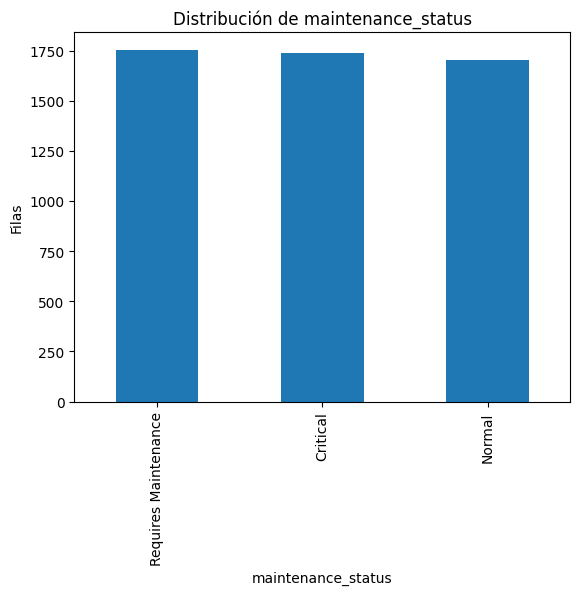

In [4]:
# Distribución de clases
conteo = df['maintenance_status'].value_counts()
print(conteo)
print((conteo / len(df)).round(3))

conteo.plot(kind='bar', title='Distribución de maintenance_status')
plt.ylabel('Filas')
plt.show()

## Exploración: resumen, atributos por motor y anomalías

Celdas 5 a 7: resumen numérico, comprobación de si los atributos del motor son fijos
y búsqueda de columnas constantes o truncadas. Cada anomalía queda con su conteo y su gráfico.

In [5]:
# Celda 5. Resumen numérico de las variables operativas
NUMERICAS = ['engine_temp', 'oil_pressure', 'fuel_consumption', 'vibration_level', 'rpm',
             'engine_load', 'coolant_temp', 'exhaust_temp', 'running_period', 'fuel_consumption_per_hour']
CATEGORICAS = ['engine_type', 'fuel_type', 'manufacturer']
ETIQUETA = 'maintenance_status'
ESTADOS = ['Normal', 'Requires Maintenance', 'Critical']   # orden de gravedad: 0, 1, 2

df[NUMERICAS].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
engine_temp,5200.0,85.068,7.244,60.525,79.896,85.044,90.285,107.358
oil_pressure,5200.0,7.281,0.750,5.000,6.724,7.484,8.000,8.000
fuel_consumption,5200.0,3937.675,2439.428,1000.000,1880.184,3458.766,5579.231,12672.543
vibration_level,5200.0,3.747,0.366,2.500,3.500,3.745,3.994,5.000
rpm,5200.0,1496.910,202.953,732.669,1362.119,1496.021,1635.905,2205.811
engine_load,5200.0,49.795,17.366,20.001,34.632,49.966,64.850,79.983
coolant_temp,5200.0,85.000,7.475,70.000,79.568,85.000,90.397,100.000
exhaust_temp,5200.0,449.829,1.303,426.124,450.000,450.000,450.000,450.000
running_period,5200.0,84.045,48.932,0.027,41.128,84.035,127.259,167.987
fuel_consumption_per_hour,5200.0,116.270,82.220,100.000,100.000,100.000,100.000,800.000


In [6]:
# Celda 6. ¿Los atributos del motor (tipo, combustible, fabricante) son fijos dentro de cada motor?
distintos = df.groupby('engine_id')[CATEGORICAS].nunique()
print('Valores distintos por motor:')
print(distintos.describe().loc[['min', 'mean', 'max']].round(2))
print('\nMotores en los que el atributo cambia entre semanas:')
print((distintos > 1).sum().to_string())
print('\nCategorías de cada atributo:')
for c in CATEGORICAS:
    print(f'- {c}: {df[c].value_counts().to_dict()}')

Valores distintos por motor:
      engine_type  fuel_type  manufacturer
min           4.0        2.0           6.0
mean          4.0        2.0           6.0
max           4.0        2.0           6.0

Motores en los que el atributo cambia entre semanas:
engine_type     50
fuel_type       50
manufacturer    50

Categorías de cada atributo:
- engine_type: {'4-stroke High-Speed': 1548, '2-stroke Medium-Speed': 1529, '4-stroke Medium-Speed': 1327, '2-stroke Low-Speed': 796}
- fuel_type: {'Diesel': 3084, 'HFO': 2116}
- manufacturer: {'MAN B&W': 1562, 'Yanmar': 1062, 'Rolls-Royce': 793, 'Wärtsilä': 743, 'Caterpillar': 527, 'Mitsubishi': 513}


                           distintos     mínimo  filas en el mínimo      máximo  filas en el máximo  coef. de variación
engine_temp                     5200    60.5249                   1    107.3577                   1              0.0852
oil_pressure                    3505     5.0000                   8      8.0000                1689              0.1030
fuel_consumption                4532  1000.0000                 669  12672.5431                   1              0.6195
vibration_level                 5197     2.5000                   4      5.0000                   1              0.0978
rpm                             5200   732.6689                   1   2205.8110                   1              0.1356
engine_load                     5200    20.0007                   1     79.9831                   1              0.3488
coolant_temp                    4969    70.0000                 117    100.0000                 116              0.0879
exhaust_temp                     162   4

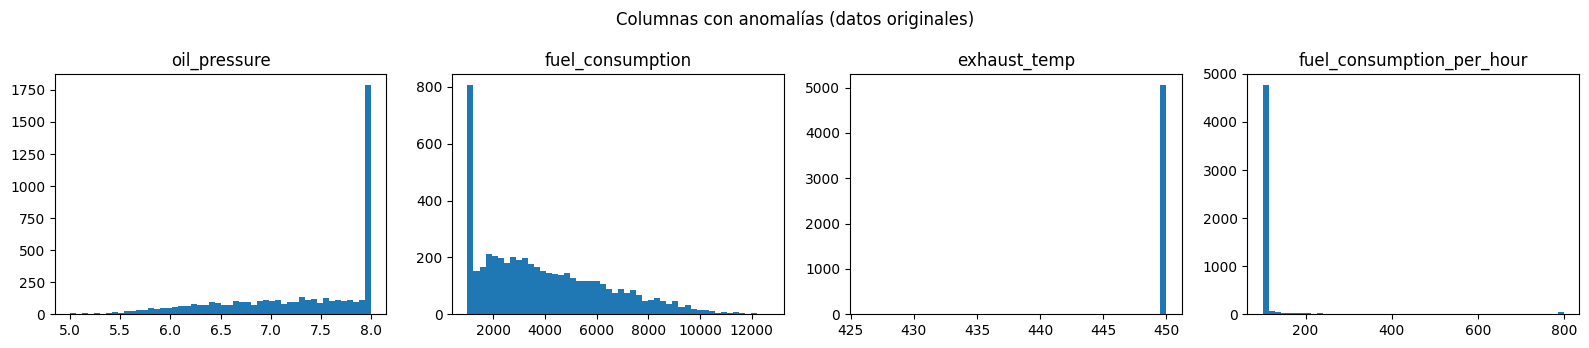


Columnas constantes o casi constantes (no entran a los modelos): []


In [7]:
# Celda 7. Columnas constantes o casi constantes y valores truncados
anomalias = pd.DataFrame({
    'distintos': df[NUMERICAS].nunique(),
    'mínimo': df[NUMERICAS].min(),
    'filas en el mínimo': [(df[c] == df[c].min()).sum() for c in NUMERICAS],
    'máximo': df[NUMERICAS].max(),
    'filas en el máximo': [(df[c] == df[c].max()).sum() for c in NUMERICAS],
    'coef. de variación': df[NUMERICAS].std() / df[NUMERICAS].mean().abs(),
})
print(anomalias.round(4).to_string())

fig, ejes = plt.subplots(1, 4, figsize=(16, 3.5))
for eje, c in zip(ejes, ['oil_pressure', 'fuel_consumption', 'exhaust_temp', 'fuel_consumption_per_hour']):
    eje.hist(df[c], bins=50)
    eje.set_title(c)
fig.suptitle('Columnas con anomalías (datos originales)')
plt.tight_layout()
plt.show()

# Regla: se elimina una columna si tiene un único valor o si su coeficiente de variación es menor a 0,1 %.
CONSTANTES = [c for c in NUMERICAS if anomalias.loc[c, 'distintos'] == 1 or anomalias.loc[c, 'coef. de variación'] < 1e-3]
print('\nColumnas constantes o casi constantes (no entran a los modelos):', CONSTANTES)

## Etiqueta, partición por motor y preprocesamiento (datos originales)

In [8]:
# Celda 8. Etiqueta: se codifica en orden de gravedad
COD_ESTADO = {e: i for i, e in enumerate(ESTADOS)}
print('Codificación:', COD_ESTADO)
print('\nfailure_mode por estado (original):')
print(pd.crosstab(df['failure_mode'], df[ETIQUETA])[ESTADOS])

Codificación: {'Normal': 0, 'Requires Maintenance': 1, 'Critical': 2}

failure_mode por estado (original):
maintenance_status  Normal  Requires Maintenance  Critical
failure_mode                                              
Mechanical Wear        436                   432       434
No Failure             343                   340       330
Oil Leakage            502                   549       554
Overheating            423                   435       422


In [9]:
# Celda 9. Partición por motor: se barajan los 50 motores con semilla fija y se toman 35, 8 y 7
def particion_por_motor(datos, semilla=SEMILLA, n_ent=35, n_val=8):
    # Reparte motores enteros entre entrenamiento, validación y prueba. Ningún motor queda en dos conjuntos.
    motores = np.array(sorted(datos['engine_id'].unique()))
    np.random.default_rng(semilla).shuffle(motores)
    grupos = {'ent': motores[:n_ent], 'val': motores[n_ent:n_ent + n_val], 'pru': motores[n_ent + n_val:]}
    assert not (set(grupos['ent']) & set(grupos['val']) or set(grupos['ent']) & set(grupos['pru'])
                or set(grupos['val']) & set(grupos['pru'])), 'Un motor está en dos conjuntos'
    partes = {k: datos[datos['engine_id'].isin(v)].sort_values(['engine_id', 'timestamp']).reset_index(drop=True)
              for k, v in grupos.items()}
    return grupos, partes

MOTORES, partes_orig = particion_por_motor(df)
for k, nombre in [('ent', 'Entrenamiento'), ('val', 'Validación'), ('pru', 'Prueba')]:
    print(f'{nombre:14s} {len(MOTORES[k]):2d} motores, {len(partes_orig[k]):5d} filas')
print('\nMotores de prueba:', sorted(map(str, MOTORES['pru'])))

Entrenamiento  35 motores,  3640 filas
Validación      8 motores,   832 filas
Prueba          7 motores,   728 filas

Motores de prueba: ['ENG_002', 'ENG_003', 'ENG_009', 'ENG_014', 'ENG_034', 'ENG_037', 'ENG_049']


In [10]:
# Celda 10. Preprocesamiento: escalado de numéricas y codificación de categóricas.
# failure_mode, engine_id y timestamp quedan fuera de las entradas. El escalador se ajusta SOLO con entrenamiento.
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ENTRADAS_NUM = [c for c in NUMERICAS if c not in CONSTANTES]

def crear_preprocesador():
    return ColumnTransformer([
        ('num', StandardScaler(), ENTRADAS_NUM),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAS),
    ])  # las columnas no listadas (failure_mode, engine_id, timestamp, etiqueta) se descartan

def preparar(partes):
    # Ajusta el preprocesador con entrenamiento y lo aplica a los tres conjuntos.
    prep = crear_preprocesador().fit(partes['ent'])
    X = {k: prep.transform(d).astype(np.float32) for k, d in partes.items()}
    y = {k: d[ETIQUETA].map(COD_ESTADO).to_numpy() for k, d in partes.items()}
    return prep, X, y

prep_orig, X_orig, y_orig = preparar(partes_orig)
print('Entradas numéricas:', ENTRADAS_NUM)
print('Entradas tras codificar:', X_orig['ent'].shape[1])
assert not any('failure_mode' in n for n in prep_orig.get_feature_names_out())

Entradas numéricas: ['engine_temp', 'oil_pressure', 'fuel_consumption', 'vibration_level', 'rpm', 'engine_load', 'coolant_temp', 'exhaust_temp', 'running_period', 'fuel_consumption_per_hour']
Entradas tras codificar: 22


In [11]:
# Celda 11. Línea base con los datos originales: clase mayoritaria, regresión logística y bosque aleatorio
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

def comparar_basicos(X, y):
    # Entrena tres modelos básicos y los evalúa en validación.
    modelos = {
        'Clase mayoritaria': DummyClassifier(strategy='most_frequent'),
        'Regresión logística': LogisticRegression(max_iter=2000),
        'Bosque aleatorio': RandomForestClassifier(n_estimators=300, random_state=SEMILLA, n_jobs=-1),
    }
    filas = []
    for nombre, m in modelos.items():
        p = m.fit(X['ent'], y['ent']).predict(X['val'])
        filas.append({'modelo': nombre, 'exactitud': accuracy_score(y['val'], p),
                      'F1 macro': f1_score(y['val'], p, average='macro')})
    return pd.DataFrame(filas).set_index('modelo')

base_orig = comparar_basicos(X_orig, y_orig)
print('Datos originales, conjunto de validación (8 motores). Azar con tres clases: 0,33')
print(base_orig.round(3))

Datos originales, conjunto de validación (8 motores). Azar con tres clases: 0,33
                     exactitud  F1 macro
modelo                                  
Clase mayoritaria        0.311     0.158
Regresión logística      0.334     0.334
Bosque aleatorio         0.344     0.344


In [12]:
# Celda 12. Comprobación de tareas alternativas: ¿hay alguna señal aprovechable en el original?
print('Medias por estado (si casi no cambian, las variables no separan las clases):')
print(df.groupby(ETIQUETA)[NUMERICAS].mean().loc[ESTADOS].T.round(3))

print('\nfailure_mode como única entrada (exactitud en validación):')
fm = {k: pd.get_dummies(d['failure_mode']).reindex(columns=sorted(df['failure_mode'].unique()), fill_value=0)
      .to_numpy(np.float32) for k, d in partes_orig.items()}
print(comparar_basicos(fm, y_orig).round(3))

def persistencia(datos):
    # Proporción de semanas cuyo estado coincide con el de la semana siguiente del mismo motor.
    sig = datos.groupby('engine_id')[ETIQUETA].shift(-1)
    ok = sig.notna()
    return float((datos.loc[ok, ETIQUETA] == sig[ok]).mean())

print(f'\nMismo estado la semana siguiente: {persistencia(df):.3f}')

def semana_siguiente(partes, prep):
    # Entradas de esta semana y estado de la semana siguiente del mismo motor.
    X, y = {}, {}
    for k, d in partes.items():
        sig = d.groupby('engine_id')[ETIQUETA].shift(-1)
        ok = sig.notna().to_numpy()
        X[k], y[k] = prep.transform(d[ok]), sig[ok].map(COD_ESTADO).to_numpy()
    return X, y

print('\nPredicción del estado de la semana siguiente:')
print(comparar_basicos(*semana_siguiente(partes_orig, prep_orig)).round(3))

Medias por estado (si casi no cambian, las variables no separan las clases):
maintenance_status           Normal  Requires Maintenance  Critical
engine_temp                  84.891                85.088    85.221
oil_pressure                  7.275                 7.270     7.299
fuel_consumption           3956.784              3843.822  4013.676
vibration_level               3.752                 3.736     3.751
rpm                        1492.265              1500.781  1497.552
engine_load                  49.724                49.257    50.407
coolant_temp                 84.796                85.110    85.089
exhaust_temp                449.811               449.836   449.842
running_period               83.732                83.496    84.907
fuel_consumption_per_hour   113.775               117.702   117.268

failure_mode como única entrada (exactitud en validación):
                     exactitud  F1 macro
modelo                                  
Clase mayoritaria        0.311   

## Modificación del dataset: tendencia de desgaste simulada

El dataset original no tiene señal: con la partición por motor, ningún modelo supera al azar (celdas 11 y 12).
El profesor indicó mantener el tema y crear la tendencia con un script propio de preprocesamiento.
Las celdas 14 a 17 hacen esa modificación.

- **Índice de desgaste por motor.** Crece cada semana según la carga (`engine_load`) y las horas de marcha
  (`running_period`) de esa semana. Cuando llega al límite, el motor recibe mantenimiento y el índice vuelve a cero.
  Cada motor tiene entre dos y cinco ciclos en sus 104 semanas.
- **Estado redefinido con el índice.** Normal por debajo de 0,55; Requires Maintenance de 0,55 a 0,80; Critical desde 0,80.
- **Tres mecanismos de deterioro.** Cada ciclo sigue uno y desvía poco a poco sus sensores:
  - Overheating: suben `coolant_temp` y `engine_temp`.
  - Oil Leakage: baja `oil_pressure` y sube un poco `engine_temp`.
  - Mechanical Wear: sube `vibration_level`, baja `rpm` y sube `fuel_consumption`.
- **El ruido original se conserva.** El desvío se suma a los valores originales, con variación aleatoria semana a semana.
- **No se tocan** `exhaust_temp` ni `fuel_consumption_per_hour`.
- **Fuera de las entradas:** `failure_mode` (tras la modificación vale No Failure solo en Normal, así que revela
  la etiqueta) y las columnas de traza `indice_desgaste` y `mecanismo`.
- **Reproducible:** semilla 42. Los parámetros se fijan antes de entrenar las redes y no se ajustan para mejorar un resultado.

**Los resultados de este notebook corresponden a un patrón de deterioro simulado, no a motores reales.**

In [13]:
# Celda 14. Parámetros de la modificación. Se fijan antes de entrenar las redes.
SEMILLA_MOD = 42
UMBRALES = {'Requires Maintenance': 0.55, 'Critical': 0.80}   # Normal por debajo de 0,55
LIMITE = 1.0                  # al llegar aquí el motor recibe mantenimiento y el índice vuelve a cero
CICLOS_POR_MOTOR = (2, 5)     # ciclos de desgaste por motor en las 104 semanas
MECANISMOS = ['Overheating', 'Oil Leakage', 'Mechanical Wear']
# Desvío que alcanza cada sensor cuando el índice llega a 1, en desviaciones estándar del original.
# Se eligió para que una sola semana no baste y el historial ayude (ver la tabla de la celda 17).
EFECTOS = {
    'Overheating':     {'coolant_temp': +4.5, 'engine_temp': +4.5},
    'Oil Leakage':     {'oil_pressure': -5.5, 'engine_temp': +2.0},
    'Mechanical Wear': {'vibration_level': +4.5, 'rpm': -3.5, 'fuel_consumption': +3.5},
}
VARIACION_EFECTO = 0.5        # variación aleatoria semanal del desvío (proporcional)
RUTA_MOD = '/kaggle/working/marine_engine_data_modificado.csv'

In [14]:
# Celda 15. Función que aplica la tendencia y guarda el CSV modificado
def estado_desde_indice(indice):
    # Normal < 0,55 ≤ Requires Maintenance < 0,80 ≤ Critical.
    return np.where(indice >= UMBRALES['Critical'], 'Critical',
                    np.where(indice >= UMBRALES['Requires Maintenance'], 'Requires Maintenance', 'Normal'))

def aplicar_tendencia(datos, semilla=SEMILLA_MOD):
    rng = np.random.default_rng(semilla)
    d = datos.sort_values(['engine_id', 'timestamp']).reset_index(drop=True).copy()
    desv = {c: datos[c].std() for efectos in EFECTOS.values() for c in efectos}
    indice = np.zeros(len(d))
    mecanismo = np.empty(len(d), dtype=object)
    for motor, filas in d.groupby('engine_id', sort=True).indices.items():
        # Ritmo semanal según carga y horas de marcha, con media 1 en cada motor.
        carga = d.loc[filas, 'engine_load'].to_numpy()
        horas = d.loc[filas, 'running_period'].to_numpy()
        ritmo = (carga / carga.mean()) * (horas / horas.mean())
        ritmo = ritmo / ritmo.mean()
        n_ciclos = rng.integers(CICLOS_POR_MOTOR[0], CICLOS_POR_MOTOR[1] + 1)
        w, mec = rng.uniform(0, 0.5), rng.choice(MECANISMOS)      # desgaste al inicio del registro
        # Desgaste total en las 104 semanas: n_ciclos − 1 mantenimientos; el último ciclo queda a medias.
        avance = LIMITE * (n_ciclos - 1 + rng.uniform(0.05, 0.99) - w) / len(filas)
        for j, i in enumerate(filas):
            indice[i], mecanismo[i] = w, mec
            w += avance * ritmo[j]
            if w >= LIMITE:                       # mantenimiento: vuelve a cero y cambia el mecanismo
                w, mec = 0.0, rng.choice(MECANISMOS)
    # Desvío de los sensores: proporcional al índice, con variación aleatoria semanal.
    for mec, efectos in EFECTOS.items():
        sel = mecanismo == mec
        for col, k in efectos.items():
            ruido = 1 + VARIACION_EFECTO * rng.standard_normal(sel.sum())
            d.loc[sel, col] = d.loc[sel, col].to_numpy() + k * desv[col] * indice[sel] * ruido
    for col in {c for efectos in EFECTOS.values() for c in efectos}:
        d[col] = d[col].clip(lower=0)             # ninguna presión, temperatura ni rpm negativa
    d['indice_desgaste'] = indice.round(4)
    d['mecanismo'] = mecanismo
    d[ETIQUETA] = estado_desde_indice(indice)
    d['failure_mode'] = np.where(d[ETIQUETA] == 'Normal', 'No Failure', mecanismo)
    return d

df_mod = aplicar_tendencia(df)
df_mod.to_csv(RUTA_MOD, index=False)
print('Guardado:', RUTA_MOD, df_mod.shape)

Guardado: /kaggle/working/marine_engine_data_modificado.csv (5200, 19)


Columnas modificadas: ['coolant_temp', 'engine_temp', 'fuel_consumption', 'oil_pressure', 'rpm', 'vibration_level']
Columnas sin tocar: ['engine_load', 'exhaust_temp', 'running_period', 'fuel_consumption_per_hour', 'engine_type', 'fuel_type', 'manufacturer']

Clases tras la modificación:
maintenance_status
Normal                  0.576
Requires Maintenance    0.247
Critical                0.176

Ciclos por motor: mínimo 2, media 3.4, máximo 5

Medias por estado de las columnas modificadas:
maintenance_status    Normal  Requires Maintenance  Critical
coolant_temp          88.048                92.645    95.369
engine_temp           89.569                95.814    98.734
fuel_consumption    4687.256              6059.285  6677.848
oil_pressure           6.929                 6.464     6.204
rpm                 1432.100              1331.709  1273.256
vibration_level        3.896                 4.143     4.282

Mismo estado la semana siguiente: original 0.317 · modificado 0.925


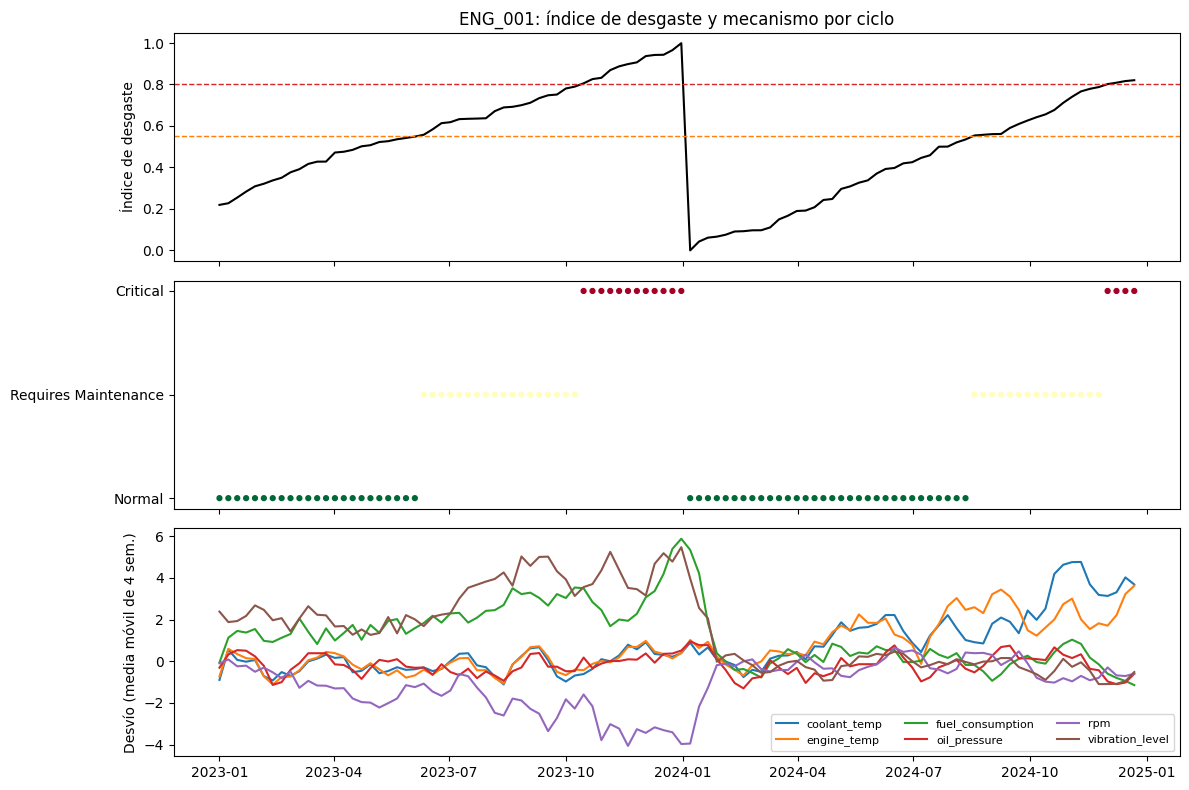

In [15]:
# Celda 16. Comprobación de la modificación
COLS_MOD = sorted({c for efectos in EFECTOS.values() for c in efectos})
df_ord = df.sort_values(['engine_id', 'timestamp']).reset_index(drop=True)
sin_tocar = [c for c in NUMERICAS + CATEGORICAS if c not in COLS_MOD]
assert all((df_ord[c] == df_mod[c]).all() for c in sin_tocar), 'Se modificó una columna que no debía tocarse'
print('Columnas modificadas:', COLS_MOD)
print('Columnas sin tocar:', sin_tocar)

print('\nClases tras la modificación:')
print(df_mod[ETIQUETA].value_counts(normalize=True).reindex(ESTADOS).round(3).to_string())

ciclos = df_mod.groupby('engine_id')['indice_desgaste'].apply(lambda s: (s.diff() < 0).sum() + 1)
print(f'\nCiclos por motor: mínimo {ciclos.min()}, media {ciclos.mean():.1f}, máximo {ciclos.max()}')

print('\nMedias por estado de las columnas modificadas:')
print(df_mod.groupby(ETIQUETA)[COLS_MOD].mean().loc[ESTADOS].T.round(3))
print(f'\nMismo estado la semana siguiente: original {persistencia(df):.3f} · modificado {persistencia(df_mod):.3f}')

# Un motor de ejemplo: índice de desgaste, estado y sensores
motor = df_mod['engine_id'].iloc[0]
m = df_mod[df_mod['engine_id'] == motor]
fig, ejes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
ejes[0].plot(m['timestamp'], m['indice_desgaste'], color='black')
for nombre, u in UMBRALES.items():
    ejes[0].axhline(u, ls='--', lw=1, color='tab:orange' if nombre == 'Requires Maintenance' else 'tab:red')
ejes[0].set_ylabel('Índice de desgaste')
ejes[0].set_title(f'{motor}: índice de desgaste y mecanismo por ciclo')
ejes[1].scatter(m['timestamp'], m[ETIQUETA].map(COD_ESTADO), c=m[ETIQUETA].map(COD_ESTADO), cmap='RdYlGn_r', s=12)
ejes[1].set_yticks(range(3), ESTADOS)
for col in COLS_MOD:
    z = (m[col] - df[col].mean()) / df[col].std()
    ejes[2].plot(m['timestamp'], z.rolling(4, min_periods=1).mean(), label=col)
ejes[2].set_ylabel('Desvío (media móvil de 4 sem.)')
ejes[2].legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.show()

In [16]:
# Celda 17. Señal antes y después de la modificación, con la partición por motor (validación)
VENTANA_PRUEBA = 8

def ventanas_planas(X, datos, T):
    # Concatena las T semanas previas (incluida la actual) de un mismo motor. Para modelos básicos.
    filas_X, filas_fin = [], []
    for filas in datos.groupby('engine_id', sort=False).indices.values():
        for k in range(T - 1, len(filas)):
            filas_X.append(X[filas[k - T + 1:k + 1]].ravel())
            filas_fin.append(filas[k])
    return np.array(filas_X), np.array(filas_fin)

def resumen_senal(datos):
    _, partes = particion_por_motor(datos)
    prep, X, y = preparar(partes)
    una = comparar_basicos(X, y)
    Xw, yw = {}, {}
    for k, d in partes.items():
        Xw[k], fin = ventanas_planas(X[k], d, VENTANA_PRUEBA)
        yw[k] = y[k][fin]
    vent = comparar_basicos(Xw, yw)
    clases = datos[ETIQUETA].value_counts(normalize=True).reindex(ESTADOS)
    return {
        'Clases (N / RM / C)': ' / '.join(f'{v:.0%}' for v in clases),
        'Mismo estado la semana siguiente': round(persistencia(datos), 3),
        'Clase mayoritaria, exactitud': round(una.loc['Clase mayoritaria', 'exactitud'], 3),
        'Bosque aleatorio con una semana, F1 macro': round(una.loc['Bosque aleatorio', 'F1 macro'], 3),
        'Regresión logística con una semana, F1 macro': round(una.loc['Regresión logística', 'F1 macro'], 3),
        f'Bosque aleatorio con ventana de {VENTANA_PRUEBA} semanas, F1 macro': round(vent.loc['Bosque aleatorio', 'F1 macro'], 3),
        f'Regresión logística con ventana de {VENTANA_PRUEBA} semanas, F1 macro': round(vent.loc['Regresión logística', 'F1 macro'], 3),
    }

tabla_senal = pd.DataFrame({'Original': resumen_senal(df), 'Modificado': resumen_senal(df_mod)})
tabla_senal

,Original,Modificado
Clases (N / RM / C),33% / 34% / 33%,58% / 25% / 18%
Mismo estado la semana siguiente,0.317,0.925
"Clase mayoritaria, exactitud",0.311,0.6
"Bosque aleatorio con una semana, F1 macro",0.344,0.608
"Regresión logística con una semana, F1 macro",0.334,0.533
"Bosque aleatorio con ventana de 8 semanas, F1 macro",0.286,0.729
"Regresión logística con ventana de 8 semanas, F1 macro",0.332,0.669


## Preparación final con los datos modificados

Las Fases 2 a 4 parten de aquí. Se usa la misma partición por motor (35 · 8 · 7) y el preprocesador se ajusta solo con entrenamiento.

In [17]:
# Celda 18. Preparación final: etiqueta, partición 35 · 8 · 7 y preprocesador, con los datos modificados
import joblib

DIR_SALIDA = '/kaggle/working/'
MOTORES_MOD, partes = particion_por_motor(df_mod)
assert all(set(MOTORES_MOD[k]) == set(MOTORES[k]) for k in MOTORES), 'La partición cambió'

df_ent, df_val, df_pru = partes['ent'], partes['val'], partes['pru']
for d in (df_ent, df_val, df_pru):
    d['estado'] = d[ETIQUETA].map(COD_ESTADO)

preprocesador, X, y = preparar(partes)
X_ent, X_val, X_pru = X['ent'], X['val'], X['pru']
y_ent, y_val, y_pru = y['ent'], y['val'], y['pru']
N_ENTRADAS = X_ent.shape[1]
NOMBRES_ENTRADAS = list(preprocesador.get_feature_names_out())

# Ninguna columna de traza ni failure_mode entre las entradas
assert not any(t in n for n in NOMBRES_ENTRADAS for t in ('failure_mode', 'indice_desgaste', 'mecanismo', 'engine_id'))
joblib.dump(preprocesador, DIR_SALIDA + 'preprocesador.joblib')

print(f'Entradas por semana: {N_ENTRADAS}')
for nombre, d, Xc in [('Entrenamiento', df_ent, X_ent), ('Validación', df_val, X_val), ('Prueba', df_pru, X_pru)]:
    dist = d[ETIQUETA].value_counts(normalize=True).reindex(ESTADOS).round(3).to_dict()
    print(f'{nombre:14s} {d["engine_id"].nunique():2d} motores {Xc.shape} {dist}')
print(f'\nLínea base (clase mayoritaria de entrenamiento) en validación: '
      f'{(y_val == np.bincount(y_ent).argmax()).mean():.3f} de exactitud')
print('Guardado:', DIR_SALIDA + 'preprocesador.joblib')

Entradas por semana: 22
Entrenamiento  35 motores (3640, 22) {'Normal': 0.568, 'Requires Maintenance': 0.253, 'Critical': 0.179}
Validación      8 motores (832, 22) {'Normal': 0.6, 'Requires Maintenance': 0.242, 'Critical': 0.159}
Prueba          7 motores (728, 22) {'Normal': 0.591, 'Requires Maintenance': 0.224, 'Critical': 0.185}

Línea base (clase mayoritaria de entrenamiento) en validación: 0.600 de exactitud
Guardado: /kaggle/working/preprocesador.joblib


# Perceptrón multicapa

Clasifica cada semana por separado con las 22 entradas preparadas en la celda 18.

- Arquitectura: capas ocultas con ReLU y dropout; salida de 3 neuronas con softmax; pérdida de entropía cruzada
  con pesos por clase (Critical es la clase menos frecuente).
- Entrenamiento: retropropagación con Adam y parada temprana según el F1 macro de validación.
- Búsqueda de parámetros: 30 combinaciones al azar de capas, neuronas, tasa de aprendizaje y regularización.
- Regla de selección, fijada antes de mirar prueba: mayor F1 macro en validación y, en empate, mayor exhaustividad en Critical.
- La configuración elegida se entrena con cinco semillas.
- Experimento aparte: el mismo perceptrón con `failure_mode` como entrada, para mostrar la fuga de información.

In [18]:
# Celda 20. Utilidades comunes de las Fases 2 a 4: semillas, métricas, entrenamiento y búsqueda
import copy, json, random, time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import precision_recall_fscore_support, classification_report, ConfusionMatrixDisplay

SEMILLAS = [42, 7, 123, 2024, 31415]
DISPOSITIVO = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
N_CLASES = len(ESTADOS)
X_ent32, X_val32, X_pru32 = (np.asarray(Xc, dtype=np.float32) for Xc in (X_ent, X_val, X_pru))
print('PyTorch', torch.__version__, '| dispositivo:', DISPOSITIVO)

def fijar_semilla(semilla):
    # Fija las semillas de Python, NumPy y PyTorch para que cada corrida sea reproducible.
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.cuda.manual_seed_all(semilla)

def pesos_clase(y):
    # Pesos inversos a la frecuencia de cada clase en entrenamiento.
    conteo = np.bincount(y, minlength=N_CLASES)
    return len(y) / (N_CLASES * np.maximum(conteo, 1))

def muestrear(espacio, n, semilla=SEMILLA):
    # n combinaciones distintas, elegidas al azar del espacio de búsqueda.
    rng = np.random.default_rng(semilla)
    vistas, combinaciones = set(), []
    while len(combinaciones) < n:
        cfg = {k: v[int(rng.integers(len(v)))] for k, v in espacio.items()}
        if tuple(cfg.values()) not in vistas:
            vistas.add(tuple(cfg.values()))
            combinaciones.append(cfg)
    return combinaciones

def metricas(y_true, y_pred):
    # Exactitud, F1 macro y precisión, exhaustividad y F1 de cada clase.
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=list(range(N_CLASES)), zero_division=0)
    m = {'exactitud': float((y_true == y_pred).mean()), 'f1_macro': float(f.mean())}
    for i, e in enumerate(ESTADOS):
        clave = e.lower().replace(' ', '_')
        m[f'precision_{clave}'], m[f'recall_{clave}'], m[f'f1_{clave}'] = float(p[i]), float(r[i]), float(f[i])
    return m

def predecir(modelo, X):
    # Devuelve la clase predicha y las probabilidades (softmax) de cada clase.
    modelo.eval()
    with torch.no_grad():
        logits = modelo(torch.as_tensor(X, dtype=torch.float32, device=DISPOSITIVO))
    return logits.argmax(1).cpu().numpy(), torch.softmax(logits, 1).cpu().numpy()

def entrenar(crear_modelo, X_tr, y_tr, X_va, y_va, lr, decaimiento, semilla, pesos,
             epocas_max=200, paciencia=20, tam_lote=64):
    # Entrena con retropropagación y Adam. Se queda con la época de mejor F1 macro en validación
    # y para si pasan `paciencia` épocas sin mejorar.
    fijar_semilla(semilla)
    modelo = crear_modelo().to(DISPOSITIVO)
    lotes = DataLoader(
        TensorDataset(torch.as_tensor(X_tr, dtype=torch.float32), torch.as_tensor(y_tr, dtype=torch.long)),
        batch_size=tam_lote, shuffle=True, generator=torch.Generator().manual_seed(semilla))
    # CrossEntropyLoss aplica softmax por dentro: el modelo entrega logits.
    perdida = nn.CrossEntropyLoss(weight=torch.as_tensor(pesos, dtype=torch.float32, device=DISPOSITIVO))
    optimizador = torch.optim.Adam(modelo.parameters(), lr=lr, weight_decay=decaimiento)
    historial = {'perdida_ent': [], 'f1_val': []}
    mejor, mejor_estado, mejor_epoca, sin_mejora = {'f1_macro': -1.0}, None, 0, 0
    for epoca in range(1, epocas_max + 1):
        modelo.train()
        total = 0.0
        for xb, yb in lotes:
            xb, yb = xb.to(DISPOSITIVO), yb.to(DISPOSITIVO)
            optimizador.zero_grad()
            l = perdida(modelo(xb), yb)
            l.backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            optimizador.step()
            total += l.item() * len(xb)
        pred, _ = predecir(modelo, X_va)
        m = metricas(y_va, pred)
        historial['perdida_ent'].append(total / len(X_tr))
        historial['f1_val'].append(m['f1_macro'])
        if m['f1_macro'] > mejor['f1_macro']:
            mejor, mejor_epoca, sin_mejora = m, epoca, 0
            mejor_estado = copy.deepcopy(modelo.state_dict())
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                break
    modelo.load_state_dict(mejor_estado)
    return modelo, mejor, mejor_epoca, historial

def graficar_historial(historial, mejor_epoca, titulo):
    # Pérdida de entrenamiento y F1 macro de validación por época, con la época elegida marcada.
    fig, ejes = plt.subplots(1, 2, figsize=(12, 3.5))
    ejes[0].plot(range(1, len(historial['perdida_ent']) + 1), historial['perdida_ent'])
    ejes[0].set_title('Pérdida en entrenamiento')
    ejes[1].plot(range(1, len(historial['f1_val']) + 1), historial['f1_val'])
    ejes[1].axvline(mejor_epoca, ls='--', color='gray', label=f'época elegida ({mejor_epoca})')
    ejes[1].set_title('F1 macro en validación')
    ejes[1].legend()
    for eje in ejes:
        eje.set_xlabel('Época')
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

PyTorch 2.11.0+cpu | dispositivo: cpu


In [19]:
# Celda 21. Clase del perceptrón y espacio de búsqueda
class PerceptronMulticapa(nn.Module):
    # Capas ocultas lineales con ReLU y dropout. La salida son 3 logits (softmax en la pérdida).
    def __init__(self, n_entradas, capas, dropout):
        super().__init__()
        bloques, anterior = [], n_entradas
        for neuronas in capas:
            bloques += [nn.Linear(anterior, neuronas), nn.ReLU(), nn.Dropout(dropout)]
            anterior = neuronas
        bloques.append(nn.Linear(anterior, N_CLASES))
        self.red = nn.Sequential(*bloques)

    def forward(self, x):
        return self.red(x)

ESPACIO_MLP = {
    'capas': [1, 2, 3],
    'neuronas': [32, 64, 128],
    'lr': [1e-2, 1e-3, 1e-4],
    'decaimiento': [0.0, 1e-4, 1e-3],
    'dropout': [0.0, 0.2, 0.4],
}
N_COMBINACIONES_MLP = 30
combinaciones_mlp = muestrear(ESPACIO_MLP, N_COMBINACIONES_MLP)
PESOS_MLP = pesos_clase(y_ent)
print(f'{N_COMBINACIONES_MLP} combinaciones de {np.prod([len(v) for v in ESPACIO_MLP.values()])} posibles')
print('Pesos por clase:', dict(zip(ESTADOS, PESOS_MLP.round(3))))
print(PerceptronMulticapa(N_ENTRADAS, [64, 64], 0.2))

30 combinaciones de 243 posibles
Pesos por clase: {'Normal': np.float64(0.587), 'Requires Maintenance': np.float64(1.316), 'Critical': np.float64(1.867)}
PerceptronMulticapa(
  (red): Sequential(
    (0): Linear(in_features=22, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=64, out_features=3, bias=True)
  )
)


In [20]:
# Celda 22. Búsqueda de parámetros del perceptrón. Toma varios minutos en CPU.
registro_mlp, historiales_mlp = [], {}
inicio = time.time()
for n, cfg in enumerate(combinaciones_mlp, 1):
    crear = lambda cfg=cfg: PerceptronMulticapa(N_ENTRADAS, [cfg['neuronas']] * cfg['capas'], cfg['dropout'])
    _, m, ep, hist = entrenar(crear, X_ent32, y_ent, X_val32, y_val,
                             cfg['lr'], cfg['decaimiento'], SEMILLA, PESOS_MLP)
    registro_mlp.append({'id': n, **cfg, 'mejor_epoca': ep, **{k: round(v, 4) for k, v in m.items()}})
    historiales_mlp[n] = hist
    print(f"{n:2d}/{N_COMBINACIONES_MLP} {cfg} -> F1 macro {m['f1_macro']:.3f} (época {ep})")
print(f'Búsqueda terminada en {(time.time() - inicio) / 60:.1f} min')

# Regla fijada antes de mirar prueba: mayor F1 macro y, en empate, mayor exhaustividad en Critical.
busqueda_mlp = pd.DataFrame(registro_mlp).sort_values(['f1_macro', 'recall_critical'], ascending=False)
busqueda_mlp.to_csv(DIR_SALIDA + 'busqueda_mlp.csv', index=False)
busqueda_mlp.head(10)

 1/30 {'capas': 1, 'neuronas': 128, 'lr': 0.001, 'decaimiento': 0.0001, 'dropout': 0.2} -> F1 macro 0.637 (época 45)
 2/30 {'capas': 3, 'neuronas': 32, 'lr': 0.0001, 'decaimiento': 0.0, 'dropout': 0.0} -> F1 macro 0.613 (época 109)
 3/30 {'capas': 2, 'neuronas': 128, 'lr': 0.0001, 'decaimiento': 0.001, 'dropout': 0.4} -> F1 macro 0.611 (época 57)
 4/30 {'capas': 3, 'neuronas': 64, 'lr': 0.01, 'decaimiento': 0.001, 'dropout': 0.2} -> F1 macro 0.649 (época 19)
 5/30 {'capas': 2, 'neuronas': 64, 'lr': 0.01, 'decaimiento': 0.001, 'dropout': 0.4} -> F1 macro 0.647 (época 10)
 6/30 {'capas': 2, 'neuronas': 64, 'lr': 0.0001, 'decaimiento': 0.0001, 'dropout': 0.2} -> F1 macro 0.610 (época 58)
 7/30 {'capas': 2, 'neuronas': 32, 'lr': 0.01, 'decaimiento': 0.0001, 'dropout': 0.4} -> F1 macro 0.651 (época 26)
 8/30 {'capas': 1, 'neuronas': 128, 'lr': 0.0001, 'decaimiento': 0.0, 'dropout': 0.2} -> F1 macro 0.619 (época 100)
 9/30 {'capas': 1, 'neuronas': 128, 'lr': 0.0001, 'decaimiento': 0.0001, 'd

,id,capas,neuronas,lr,decaimiento,dropout,mejor_epoca,exactitud,f1_macro,precision_normal,recall_normal,f1_normal,precision_requires_maintenance,recall_requires_maintenance,f1_requires_maintenance,precision_critical,recall_critical,f1_critical
25,26,3,32,0.010,0.0001,0.4,29,0.7332,0.6630,0.8800,0.8377,0.8583,0.4896,0.5871,0.5339,0.6379,0.5606,0.5968
6,7,2,32,0.010,0.0001,0.4,26,0.6959,0.6515,0.9152,0.7355,0.8156,0.4313,0.6866,0.5298,0.6667,0.5606,0.6091
3,4,3,64,0.010,0.0010,0.2,19,0.7091,0.6488,0.8837,0.7916,0.8351,0.4525,0.5920,0.5129,0.6230,0.5758,0.5984
15,16,3,32,0.010,0.0010,0.4,26,0.7055,0.6481,0.9069,0.7615,0.8279,0.4483,0.7114,0.5500,0.6809,0.4848,0.5664
26,27,3,32,0.010,0.0010,0.0,30,0.7067,0.6480,0.8643,0.7916,0.8264,0.4570,0.5821,0.5120,0.6387,0.5758,0.6056
23,24,2,64,0.010,0.0001,0.4,21,0.7188,0.6476,0.8708,0.8236,0.8465,0.4715,0.5771,0.5190,0.6228,0.5379,0.5772
4,5,2,64,0.010,0.0010,0.4,10,0.7236,0.6472,0.8598,0.8477,0.8537,0.4787,0.5025,0.4903,0.6047,0.5909,0.5977
10,11,3,32,0.001,0.0001,0.2,25,0.7188,0.6423,0.8811,0.8317,0.8557,0.4732,0.5274,0.4988,0.5620,0.5833,0.5725
11,12,1,64,0.010,0.0010,0.4,18,0.7091,0.6397,0.8672,0.8116,0.8385,0.4575,0.5622,0.5045,0.6102,0.5455,0.5760
13,14,1,128,0.001,0.0000,0.2,45,0.7151,0.6390,0.8822,0.8257,0.8530,0.4693,0.5323,0.4988,0.5547,0.5758,0.5651


Configuración elegida: {'capas': 3, 'neuronas': 32, 'lr': 0.01, 'decaimiento': 0.0001, 'dropout': 0.4}
F1 macro en validación 0.663 | exactitud 0.733 | exhaustividad Critical 0.561


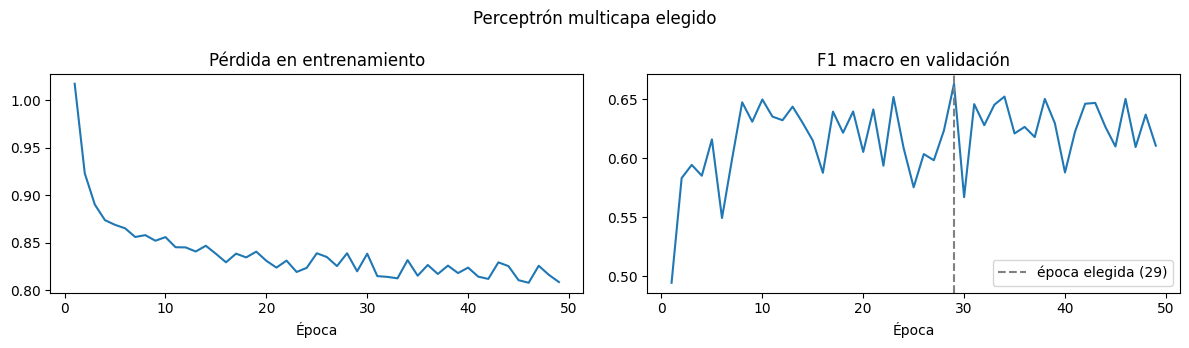

In [21]:
# Celda 23. Configuración elegida del perceptrón
fila = busqueda_mlp.iloc[0]
CONFIG_MLP = {'capas': int(fila['capas']), 'neuronas': int(fila['neuronas']), 'lr': float(fila['lr']),
              'decaimiento': float(fila['decaimiento']), 'dropout': float(fila['dropout'])}
print('Configuración elegida:', CONFIG_MLP)
print(f"F1 macro en validación {fila['f1_macro']:.3f} | exactitud {fila['exactitud']:.3f} | "
      f"exhaustividad Critical {fila['recall_critical']:.3f}")
graficar_historial(historiales_mlp[int(fila['id'])], int(fila['mejor_epoca']), 'Perceptrón multicapa elegido')

In [22]:
# Celda 24. La configuración elegida, entrenada con las cinco semillas, y guardado de los pesos
def crear_mlp():
    return PerceptronMulticapa(N_ENTRADAS, [CONFIG_MLP['neuronas']] * CONFIG_MLP['capas'], CONFIG_MLP['dropout'])

estados_mlp, filas = [], []
for s in SEMILLAS:
    modelo, m, ep, _ = entrenar(crear_mlp, X_ent32, y_ent, X_val32, y_val,
                                CONFIG_MLP['lr'], CONFIG_MLP['decaimiento'], s, PESOS_MLP)
    estados_mlp.append({k: v.cpu() for k, v in modelo.state_dict().items()})
    filas.append({'semilla': s, 'mejor_epoca': ep, **m})
semillas_mlp = pd.DataFrame(filas)
print(semillas_mlp[['semilla', 'mejor_epoca', 'exactitud', 'f1_macro', 'recall_critical']].round(3).to_string(index=False))
print('\nMedia y desviación:')
print(semillas_mlp[['exactitud', 'f1_macro', 'recall_critical']].agg(['mean', 'std']).round(3))

torch.save({'config': CONFIG_MLP, 'n_entradas': N_ENTRADAS, 'semillas': SEMILLAS, 'estados': estados_mlp},
           DIR_SALIDA + 'mlp.pt')
print('Guardado:', DIR_SALIDA + 'mlp.pt')

 semilla  mejor_epoca  exactitud  f1_macro  recall_critical
      42           29      0.733     0.663            0.561
       7            7      0.730     0.660            0.500
     123           12      0.728     0.654            0.470
    2024           13      0.709     0.638            0.477
   31415           37      0.726     0.657            0.545

Media y desviación:
      exactitud  f1_macro  recall_critical
mean      0.725     0.654            0.511
std       0.009     0.010            0.041
Guardado: /kaggle/working/mlp.pt


                      precision    recall  f1-score   support

              Normal      0.880     0.838     0.858       499
Requires Maintenance      0.490     0.587     0.534       201
            Critical      0.638     0.561     0.597       132

            accuracy                          0.733       832
           macro avg      0.669     0.662     0.663       832
        weighted avg      0.747     0.733     0.738       832



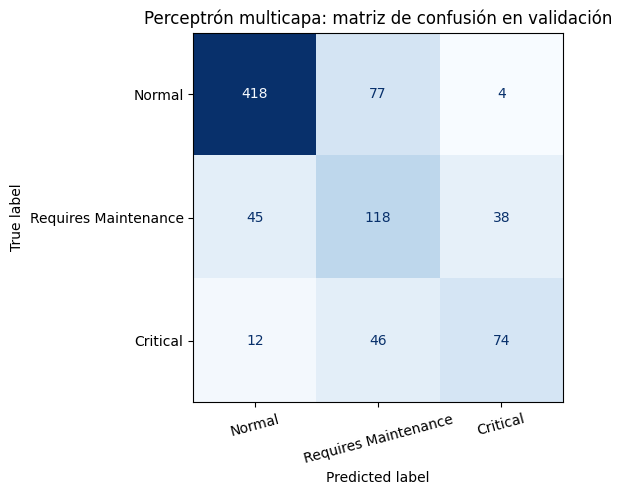

In [23]:
# Celda 25. Detalle por clase en validación, con la semilla 42
mlp = crear_mlp().to(DISPOSITIVO)
mlp.load_state_dict(estados_mlp[0])
pred_val_mlp, prob_val_mlp = predecir(mlp, X_val32)
print(classification_report(y_val, pred_val_mlp, target_names=ESTADOS, digits=3))
ConfusionMatrixDisplay.from_predictions(y_val, pred_val_mlp, display_labels=ESTADOS, cmap='Blues', colorbar=False)
plt.title('Perceptrón multicapa: matriz de confusión en validación')
plt.xticks(rotation=15)
plt.show()

In [24]:
# Celda 26. Experimento aparte: el mismo perceptrón con failure_mode como entrada (fuga de información)
COLS_FM = sorted(df_mod['failure_mode'].unique())

def con_failure_mode(Xc, d):
    # Agrega failure_mode codificado a las entradas. Solo para este experimento.
    fm = pd.get_dummies(d['failure_mode']).reindex(columns=COLS_FM, fill_value=0).to_numpy(np.float32)
    return np.hstack([Xc, fm])

X_ent_fm, X_val_fm = con_failure_mode(X_ent32, df_ent), con_failure_mode(X_val32, df_val)
crear_fm = lambda: PerceptronMulticapa(X_ent_fm.shape[1], [CONFIG_MLP['neuronas']] * CONFIG_MLP['capas'],
                                       CONFIG_MLP['dropout'])
_, m_fm, _, _ = entrenar(crear_fm, X_ent_fm, y_ent, X_val_fm, y_val,
                         CONFIG_MLP['lr'], CONFIG_MLP['decaimiento'], SEMILLA, PESOS_MLP)
cols = ['exactitud', 'f1_macro', 'recall_critical']
print(pd.DataFrame({'sin failure_mode': semillas_mlp.iloc[0][cols],
                    'con failure_mode': pd.Series(m_fm)[cols]}).astype(float).round(3))
print('\nfailure_mode por estado (entrenamiento):')
print(pd.crosstab(df_ent['failure_mode'], df_ent[ETIQUETA])[ESTADOS])

                 sin failure_mode  con failure_mode
exactitud                   0.733             0.859
f1_macro                    0.663             0.762
recall_critical             0.561             0.652

failure_mode por estado (entrenamiento):
maintenance_status  Normal  Requires Maintenance  Critical
failure_mode                                              
Mechanical Wear          0                   336       222
No Failure            2068                     0         0
Oil Leakage              0                   265       206
Overheating              0                   321       222


# Red recurrente

Clasifica cada semana mirando las T semanas anteriores del mismo motor. La etiqueta de cada ventana es el estado de su última semana.

- Ventanas de 4, 8 o 12 semanas. Ninguna ventana cruza de un motor a otro.
- Celda LSTM o GRU, 32 o 64 unidades y 1 o 2 capas. Mismo ciclo de entrenamiento, misma parada temprana
  y misma regla de selección que el perceptrón.
- Validación y prueba usan solo las semanas desde la 12 de cada motor, para que todas las T y el perceptrón
  se comparen sobre las mismas filas.
- La configuración elegida se entrena con las mismas cinco semillas.

In [25]:
# Celda 28. Ventanas semanales por motor y comprobaciones
T_OPCIONES = [4, 8, 12]
POS_MIN = max(T_OPCIONES) - 1   # semana 12 de cada motor: desde ahí existe ventana para cualquier T

def crear_ventanas(X, datos, T, desde=None):
    # Ventanas de T semanas seguidas de un mismo motor. La etiqueta es el estado de la última semana.
    # `desde` es la posición (dentro del motor) de la primera semana que se usa como final de ventana.
    desde = T - 1 if desde is None else desde
    estados = datos['estado'].to_numpy()
    Xs, ys, filas_fin = [], [], []
    for filas in datos.groupby('engine_id', sort=False).indices.values():
        for k in range(desde, len(filas)):
            sel = filas[k - T + 1:k + 1]
            Xs.append(X[sel])
            ys.append(estados[filas[k]])
            filas_fin.append(filas[k])
    return np.stack(Xs).astype(np.float32), np.array(ys), np.array(filas_fin)

# Las semanas de cada motor deben estar en orden.
for d in (df_ent, df_val, df_pru):
    assert d.groupby('engine_id')['timestamp'].apply(lambda s: s.is_monotonic_increasing).all()

# Entrenamiento: todas las ventanas posibles. Validación y prueba: solo las semanas desde POS_MIN,
# para que todas las T y el perceptrón se comparen sobre las mismas filas.
VENTANAS = {}
for T in T_OPCIONES:
    VENTANAS[T] = {'ent': crear_ventanas(X_ent32, df_ent, T),
                   'val': crear_ventanas(X_val32, df_val, T, desde=POS_MIN),
                   'pru': crear_ventanas(X_pru32, df_pru, T, desde=POS_MIN)}
    for nombre, d, X in (('ent', df_ent, X_ent32), ('val', df_val, X_val32), ('pru', df_pru, X_pru32)):
        Xw, yw, fin = VENTANAS[T][nombre]
        ids = d['engine_id'].to_numpy()
        assert (ids[fin - (T - 1)] == ids[fin]).all(), 'Una ventana cruza de un motor a otro'
        assert (yw == d['estado'].to_numpy()[fin]).all()
        assert np.allclose(Xw[:, -1, :], X[fin])
    print(f"T = {T:2d} | entrenamiento {VENTANAS[T]['ent'][0].shape} | "
          f"validación {VENTANAS[T]['val'][0].shape} | prueba {VENTANAS[T]['pru'][0].shape}")
print('Comprobado: ninguna ventana cruza de un motor a otro.')

T =  4 | entrenamiento (3535, 4, 22) | validación (744, 4, 22) | prueba (651, 4, 22)
T =  8 | entrenamiento (3395, 8, 22) | validación (744, 8, 22) | prueba (651, 8, 22)
T = 12 | entrenamiento (3255, 12, 22) | validación (744, 12, 22) | prueba (651, 12, 22)
Comprobado: ninguna ventana cruza de un motor a otro.


In [26]:
# Celda 29. Clase de la red recurrente y espacio de búsqueda
class RedRecurrente(nn.Module):
    # LSTM o GRU sobre la ventana. La salida de la última semana pasa a una capa lineal con 3 logits.
    def __init__(self, n_entradas, celda, unidades, capas, dropout):
        super().__init__()
        tipo = nn.LSTM if celda == 'LSTM' else nn.GRU
        self.rnn = tipo(n_entradas, unidades, num_layers=capas, batch_first=True,
                        dropout=dropout if capas > 1 else 0.0)
        self.salida = nn.Sequential(nn.Dropout(dropout), nn.Linear(unidades, N_CLASES))

    def forward(self, x):
        h, _ = self.rnn(x)
        return self.salida(h[:, -1, :])

ESPACIO_RNN = {
    'T': T_OPCIONES,
    'celda': ['LSTM', 'GRU'],
    'unidades': [32, 64],
    'capas': [1, 2],
    'lr': [1e-2, 1e-3],
    'decaimiento': [0.0, 1e-4],
    'dropout': [0.0, 0.2],
}
N_COMBINACIONES_RNN = 24
combinaciones_rnn = muestrear(ESPACIO_RNN, N_COMBINACIONES_RNN)
print(f'{N_COMBINACIONES_RNN} combinaciones de {np.prod([len(v) for v in ESPACIO_RNN.values()])} posibles')
print(RedRecurrente(N_ENTRADAS, 'LSTM', 64, 2, 0.2))

24 combinaciones de 192 posibles
RedRecurrente(
  (rnn): LSTM(22, 64, num_layers=2, batch_first=True, dropout=0.2)
  (salida): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=64, out_features=3, bias=True)
  )
)


In [27]:
# Celda 30. Búsqueda de parámetros de la red recurrente. Toma más que la del perceptrón.
registro_rnn, historiales_rnn = [], {}
inicio = time.time()
for n, cfg in enumerate(combinaciones_rnn, 1):
    Xw_ent, yw_ent, _ = VENTANAS[cfg['T']]['ent']
    Xw_val, yw_val, _ = VENTANAS[cfg['T']]['val']
    crear = lambda cfg=cfg: RedRecurrente(N_ENTRADAS, cfg['celda'], cfg['unidades'], cfg['capas'], cfg['dropout'])
    _, m, ep, hist = entrenar(crear, Xw_ent, yw_ent, Xw_val, yw_val,
                             cfg['lr'], cfg['decaimiento'], SEMILLA, pesos_clase(yw_ent))
    registro_rnn.append({'id': n, **cfg, 'mejor_epoca': ep, **{k: round(v, 4) for k, v in m.items()}})
    historiales_rnn[n] = hist
    print(f"{n:2d}/{N_COMBINACIONES_RNN} {cfg} -> F1 macro {m['f1_macro']:.3f} (época {ep})")
print(f'Búsqueda terminada en {(time.time() - inicio) / 60:.1f} min')

busqueda_rnn = pd.DataFrame(registro_rnn).sort_values(['f1_macro', 'recall_critical'], ascending=False)
busqueda_rnn.to_csv(DIR_SALIDA + 'busqueda_rnn.csv', index=False)
print('\nMejor F1 macro por largo de ventana:')
print(busqueda_rnn.groupby('T')['f1_macro'].max().round(3))
busqueda_rnn.head(10)

 1/24 {'T': 4, 'celda': 'GRU', 'unidades': 64, 'capas': 1, 'lr': 0.01, 'decaimiento': 0.0001, 'dropout': 0.0} -> F1 macro 0.688 (época 3)
 2/24 {'T': 12, 'celda': 'LSTM', 'unidades': 32, 'capas': 2, 'lr': 0.001, 'decaimiento': 0.0001, 'dropout': 0.2} -> F1 macro 0.693 (época 4)
 3/24 {'T': 12, 'celda': 'GRU', 'unidades': 64, 'capas': 1, 'lr': 0.001, 'decaimiento': 0.0, 'dropout': 0.2} -> F1 macro 0.713 (época 26)
 4/24 {'T': 8, 'celda': 'LSTM', 'unidades': 64, 'capas': 2, 'lr': 0.001, 'decaimiento': 0.0, 'dropout': 0.2} -> F1 macro 0.741 (época 18)
 5/24 {'T': 8, 'celda': 'LSTM', 'unidades': 32, 'capas': 1, 'lr': 0.01, 'decaimiento': 0.0001, 'dropout': 0.2} -> F1 macro 0.734 (época 7)
 6/24 {'T': 4, 'celda': 'GRU', 'unidades': 64, 'capas': 1, 'lr': 0.001, 'decaimiento': 0.0, 'dropout': 0.2} -> F1 macro 0.693 (época 7)
 7/24 {'T': 12, 'celda': 'LSTM', 'unidades': 32, 'capas': 2, 'lr': 0.01, 'decaimiento': 0.0001, 'dropout': 0.2} -> F1 macro 0.709 (época 8)
 8/24 {'T': 12, 'celda': 'GRU'

,id,T,celda,unidades,capas,lr,decaimiento,dropout,mejor_epoca,exactitud,f1_macro,precision_normal,recall_normal,f1_normal,precision_requires_maintenance,recall_requires_maintenance,f1_requires_maintenance,precision_critical,recall_critical,f1_critical
15,16,8,LSTM,64,2,0.010,0.0000,0.0,2,0.7782,0.7432,0.9138,0.8475,0.8794,0.5783,0.6683,0.6200,0.7328,0.7273,0.7300
3,4,8,LSTM,64,2,0.001,0.0000,0.2,18,0.7836,0.7409,0.9412,0.8523,0.8945,0.5830,0.7236,0.6457,0.7073,0.6591,0.6824
12,13,8,GRU,32,1,0.001,0.0001,0.0,19,0.7688,0.7393,0.9233,0.8160,0.8663,0.5643,0.6834,0.6182,0.7174,0.7500,0.7333
8,9,8,LSTM,64,2,0.001,0.0001,0.0,16,0.7849,0.7375,0.9209,0.8741,0.8969,0.6161,0.6533,0.6341,0.6596,0.7045,0.6813
21,22,8,GRU,32,2,0.001,0.0001,0.2,11,0.7728,0.7373,0.9016,0.8426,0.8711,0.5915,0.6332,0.6117,0.6966,0.7652,0.7292
4,5,8,LSTM,32,1,0.010,0.0001,0.2,7,0.7836,0.7336,0.9022,0.8935,0.8978,0.6150,0.5779,0.5959,0.6689,0.7500,0.7071
23,24,8,LSTM,32,1,0.001,0.0001,0.2,16,0.7702,0.7290,0.9299,0.8354,0.8801,0.5774,0.6935,0.6301,0.6716,0.6818,0.6767
18,19,8,GRU,32,2,0.010,0.0000,0.0,2,0.7728,0.7265,0.8916,0.8765,0.8840,0.5837,0.6131,0.5980,0.7054,0.6894,0.6973
13,14,12,GRU,32,2,0.010,0.0000,0.2,35,0.7675,0.7264,0.8937,0.8547,0.8738,0.5833,0.5980,0.5906,0.6828,0.7500,0.7148
22,23,8,LSTM,32,1,0.001,0.0000,0.0,11,0.7648,0.7236,0.9293,0.8281,0.8758,0.5702,0.6935,0.6259,0.6642,0.6742,0.6692


Configuración elegida: {'T': 8, 'celda': 'LSTM', 'unidades': 64, 'capas': 2, 'lr': 0.01, 'decaimiento': 0.0, 'dropout': 0.0}
F1 macro en validación 0.743 | exactitud 0.778 | exhaustividad Critical 0.727


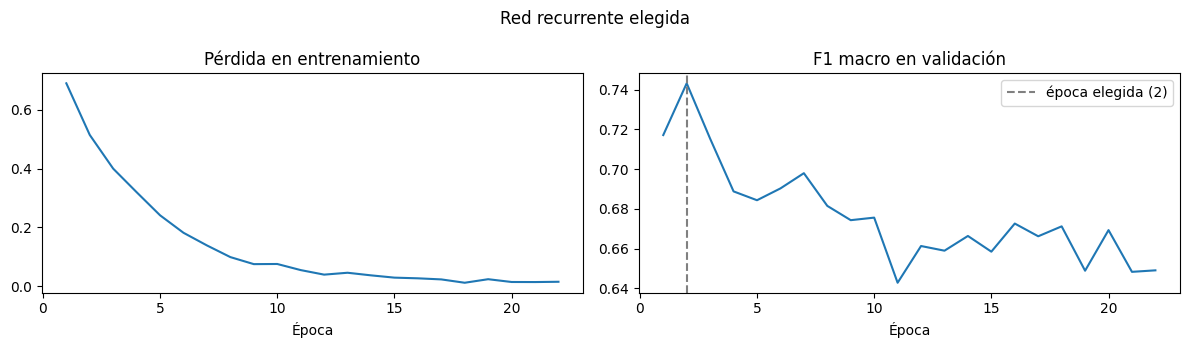

 semilla  mejor_epoca  exactitud  f1_macro  recall_critical
      42            2      0.778     0.743            0.727
       7            2      0.761     0.722            0.818
     123            1      0.770     0.717            0.720
    2024            2      0.774     0.744            0.803
   31415            1      0.769     0.699            0.500

Media y desviación:
      exactitud  f1_macro  recall_critical
mean      0.770     0.725            0.714
std       0.007     0.019            0.127
Guardado: /kaggle/working/rnn.pt y /kaggle/working/config.json


In [28]:
# Celda 31. Configuración elegida de la red recurrente, cinco semillas y guardado
import json

fila = busqueda_rnn.iloc[0]
CONFIG_RNN = {'T': int(fila['T']), 'celda': str(fila['celda']), 'unidades': int(fila['unidades']),
              'capas': int(fila['capas']), 'lr': float(fila['lr']),
              'decaimiento': float(fila['decaimiento']), 'dropout': float(fila['dropout'])}
T_RNN = CONFIG_RNN['T']
print('Configuración elegida:', CONFIG_RNN)
print(f"F1 macro en validación {fila['f1_macro']:.3f} | exactitud {fila['exactitud']:.3f} | "
      f"exhaustividad Critical {fila['recall_critical']:.3f}")
graficar_historial(historiales_rnn[int(fila['id'])], int(fila['mejor_epoca']), 'Red recurrente elegida')

def crear_rnn():
    return RedRecurrente(N_ENTRADAS, CONFIG_RNN['celda'], CONFIG_RNN['unidades'],
                         CONFIG_RNN['capas'], CONFIG_RNN['dropout'])

Xw_ent, yw_ent, _ = VENTANAS[T_RNN]['ent']
Xw_val, yw_val, fin_val = VENTANAS[T_RNN]['val']

estados_rnn, filas = [], []
for s in SEMILLAS:
    modelo, m, ep, _ = entrenar(crear_rnn, Xw_ent, yw_ent, Xw_val, yw_val,
                                CONFIG_RNN['lr'], CONFIG_RNN['decaimiento'], s, pesos_clase(yw_ent))
    estados_rnn.append({k: v.cpu() for k, v in modelo.state_dict().items()})
    filas.append({'semilla': s, 'mejor_epoca': ep, **m})
semillas_rnn = pd.DataFrame(filas)
print(semillas_rnn[['semilla', 'mejor_epoca', 'exactitud', 'f1_macro', 'recall_critical']].round(3).to_string(index=False))
print('\nMedia y desviación:')
print(semillas_rnn[['exactitud', 'f1_macro', 'recall_critical']].agg(['mean', 'std']).round(3))

torch.save({'config': CONFIG_RNN, 'n_entradas': N_ENTRADAS, 'semillas': SEMILLAS, 'estados': estados_rnn},
           DIR_SALIDA + 'rnn.pt')
with open(DIR_SALIDA + 'config.json', 'w') as f:
    json.dump({'mlp': CONFIG_MLP, 'rnn': CONFIG_RNN, 'semillas': SEMILLAS, 'pos_min': POS_MIN}, f, indent=2)
print('Guardado:', DIR_SALIDA + 'rnn.pt', 'y', DIR_SALIDA + 'config.json')


Validación: 744 filas de 8 motores

                           exactitud        f1_macro        recall_critical  \
                                mean    std     mean    std            mean   
modelo                                                                        
Clase mayoritaria              0.555    NaN    0.238    NaN           0.000   
Perceptrón multicapa           0.708  0.010    0.653  0.011           0.511   
Red recurrente (LSTM, T=8)     0.770  0.007    0.725  0.019           0.714   

                                   
                              std  
modelo                             
Clase mayoritaria             NaN  
Perceptrón multicapa        0.041  
Red recurrente (LSTM, T=8)  0.127  


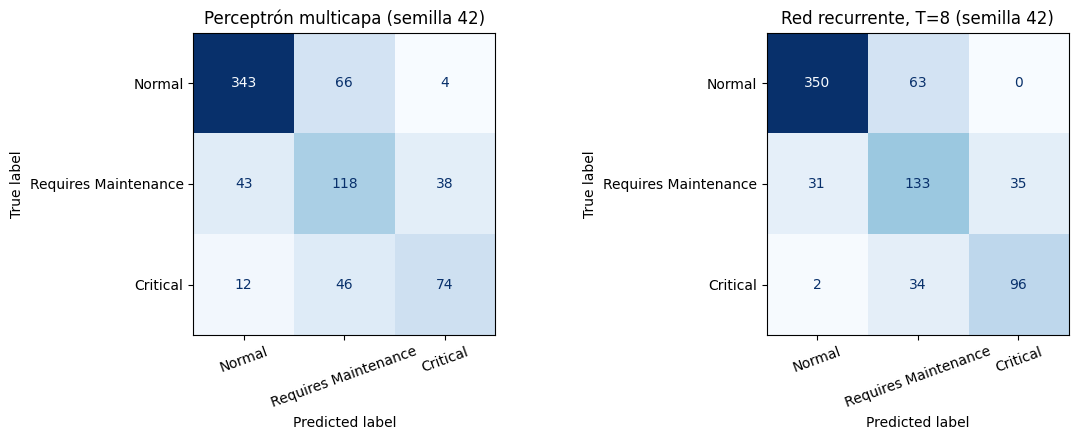

Perceptrón: Critical clasificados como Normal = 12 de 132
Red recurrente: Critical clasificados como Normal = 2 de 132


In [29]:
# Celda 32. Comparación en validación, sobre las mismas filas (semana 12 en adelante de cada motor).
# El conjunto de prueba queda reservado para la Fase 4.
pos_val = df_val.groupby('engine_id').cumcount().to_numpy()
comunes = np.where(pos_val >= POS_MIN)[0]
assert (comunes == fin_val).all(), 'Las filas del perceptrón y de la red recurrente no coinciden'
y_com = y_val[comunes]

filas = []
mayoritaria = np.full(len(y_com), np.bincount(y_ent).argmax())
filas.append({'modelo': 'Clase mayoritaria', 'semilla': '-', **metricas(y_com, mayoritaria)})
pred_mlp, pred_rnn = {}, {}
for s, est_m, est_r in zip(SEMILLAS, estados_mlp, estados_rnn):
    mlp = crear_mlp().to(DISPOSITIVO); mlp.load_state_dict(est_m)
    rnn = crear_rnn().to(DISPOSITIVO); rnn.load_state_dict(est_r)
    pred_mlp[s], _ = predecir(mlp, X_val32[comunes])
    pred_rnn[s], _ = predecir(rnn, Xw_val)
    filas.append({'modelo': 'Perceptrón multicapa', 'semilla': s, **metricas(y_com, pred_mlp[s])})
    filas.append({'modelo': f"Red recurrente ({CONFIG_RNN['celda']}, T={T_RNN})", 'semilla': s,
                  **metricas(y_com, pred_rnn[s])})
comparacion_val = pd.DataFrame(filas)
resumen = comparacion_val.groupby('modelo', sort=False)[['exactitud', 'f1_macro', 'recall_critical']].agg(['mean', 'std'])
print(f"Validación: {len(y_com)} filas de {df_val['engine_id'].nunique()} motores\n")
print(resumen.round(3))

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
for eje, (nombre, pred) in zip(ejes, (('Perceptrón multicapa', pred_mlp[SEMILLA]),
                                      (f'Red recurrente, T={T_RNN}', pred_rnn[SEMILLA]))):
    ConfusionMatrixDisplay.from_predictions(y_com, pred, display_labels=ESTADOS, ax=eje,
                                            xticks_rotation=20, cmap='Blues', colorbar=False)
    eje.set_title(f'{nombre} (semilla {SEMILLA})')
plt.tight_layout(); plt.show()

for nombre, pred in (('Perceptrón', pred_mlp[SEMILLA]), ('Red recurrente', pred_rnn[SEMILLA])):
    print(f'{nombre}: Critical clasificados como Normal = {int(((y_com == 2) & (pred == 0)).sum())} '
          f'de {int((y_com == 2).sum())}')


# Evaluación en prueba

Los dos modelos se cargan desde `mlp.pt` y `rnn.pt` y se evalúan una sola vez en el conjunto de prueba (7 motores que no se usaron para entrenar ni para elegir parámetros).

- Mismas filas para los dos modelos: semana 12 en adelante de cada motor de prueba.
- Cinco semillas por modelo: se reporta media y desviación.
- Métricas: exactitud, precisión, exhaustividad y F1 por clase y macro; verdaderos y falsos positivos y negativos por clase (cada clase contra las otras dos); matriz de confusión; casos Critical clasificados como Normal.
- Prueba de McNemar para saber si la diferencia entre los modelos es real.
- Evolución semanal de la probabilidad de cada estado en un motor de prueba.


In [30]:
# Celda 34. Se cargan los modelos desde los archivos guardados (así se comprueba que sirven para la interfaz)
# y se evalúan UNA sola vez en prueba, sobre las mismas filas para los dos modelos.
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, accuracy_score, recall_score

ckpt_mlp = torch.load(DIR_SALIDA + 'mlp.pt', map_location=DISPOSITIVO, weights_only=True)
ckpt_rnn = torch.load(DIR_SALIDA + 'rnn.pt', map_location=DISPOSITIVO, weights_only=True)
cm_, cr_ = ckpt_mlp['config'], ckpt_rnn['config']
T_PRU = cr_['T']

def cargar_mlp(estado):
    m = PerceptronMulticapa(ckpt_mlp['n_entradas'], [cm_['neuronas']] * cm_['capas'], cm_['dropout']).to(DISPOSITIVO)
    m.load_state_dict(estado)
    return m

def cargar_rnn(estado):
    m = RedRecurrente(ckpt_rnn['n_entradas'], cr_['celda'], cr_['unidades'], cr_['capas'], cr_['dropout']).to(DISPOSITIVO)
    m.load_state_dict(estado)
    return m

# Filas comunes de prueba: semana 12 en adelante de cada motor de prueba.
pos_pru = df_pru.groupby('engine_id').cumcount().to_numpy()
comunes_pru = np.where(pos_pru >= POS_MIN)[0]
Xw_pru, yw_pru, fin_pru = VENTANAS[T_PRU]['pru']
assert (comunes_pru == fin_pru).all(), 'Las filas de prueba del perceptrón y de la red recurrente no coinciden'
y_test = y_pru[comunes_pru]

pred_test, prob_test = {'mlp': {}, 'rnn': {}}, {'mlp': {}, 'rnn': {}}
for s, est_m, est_r in zip(ckpt_mlp['semillas'], ckpt_mlp['estados'], ckpt_rnn['estados']):
    pred_test['mlp'][s], prob_test['mlp'][s] = predecir(cargar_mlp(est_m), X_pru32[comunes_pru])
    pred_test['rnn'][s], prob_test['rnn'][s] = predecir(cargar_rnn(est_r), Xw_pru)

NOMBRE_MODELO = {'mlp': 'Perceptrón multicapa', 'rnn': f"Red recurrente ({cr_['celda']}, T={T_PRU})"}
CLASE_MAYORITARIA = int(np.bincount(y_ent).argmax())
print(f"Prueba: {len(y_test)} filas de {df_pru['engine_id'].nunique()} motores")
print('Distribución real:', dict(zip(ESTADOS, np.bincount(y_test, minlength=N_CLASES).tolist())))


Prueba: 651 filas de 7 motores
Distribución real: {'Normal': 359, 'Requires Maintenance': 157, 'Critical': 135}


In [31]:
# Celda 35. Resultado principal: media y desviación de las cinco semillas, frente a la línea base.
def resumen_global(y, pred):
    p, r, f, _ = precision_recall_fscore_support(y, pred, average='macro', zero_division=0)
    return {'exactitud': accuracy_score(y, pred), 'precision_macro': p, 'exhaustividad_macro': r,
            'f1_macro': f, 'recall_critical': recall_score(y, pred, labels=[2], average='macro', zero_division=0),
            'critical_como_normal': int(((y == 2) & (pred == 0)).sum())}

filas = [{'modelo': 'Clase mayoritaria', 'semilla': '-',
          **resumen_global(y_test, np.full(len(y_test), CLASE_MAYORITARIA))}]
for clave in ('mlp', 'rnn'):
    for s, pred in pred_test[clave].items():
        filas.append({'modelo': NOMBRE_MODELO[clave], 'semilla': s, **resumen_global(y_test, pred)})
resultados_test = pd.DataFrame(filas)

cols = ['exactitud', 'precision_macro', 'exhaustividad_macro', 'f1_macro', 'recall_critical', 'critical_como_normal']
tabla_principal = resultados_test.groupby('modelo', sort=False)[cols].agg(['mean', 'std'])
print(tabla_principal.round(3).to_string())
print(f'\nCasos Critical en prueba: {int((y_test == 2).sum())}')


                           exactitud        precision_macro        exhaustividad_macro        f1_macro        recall_critical        critical_como_normal       
                                mean    std            mean    std                mean    std     mean    std            mean    std                 mean    std
modelo                                                                                                                                                          
Clase mayoritaria              0.551    NaN           0.184    NaN               0.333    NaN    0.237    NaN           0.000    NaN                135.0    NaN
Perceptrón multicapa           0.692  0.004           0.655  0.011               0.626  0.008    0.633  0.007           0.517  0.037                 14.2  1.924
Red recurrente (LSTM, T=8)     0.813  0.016           0.784  0.019               0.779  0.028    0.776  0.020           0.735  0.102                  1.8  1.304

Casos Critical en prueba: 135


In [32]:
# Celda 36. Detalle por clase (cada clase contra las otras dos): verdaderos y falsos positivos y negativos.
def detalle_por_clase(y, pred):
    cm = confusion_matrix(y, pred, labels=range(N_CLASES))
    total = cm.sum()
    filas = []
    for i, nombre in enumerate(ESTADOS):
        vp = cm[i, i]; fn = cm[i].sum() - vp; fp = cm[:, i].sum() - vp; vn = total - vp - fn - fp
        filas.append({'clase': nombre, 'VP': vp, 'FP': fp, 'FN': fn, 'VN': vn,
                      'precisión': vp / (vp + fp) if vp + fp else 0.0,
                      'exhaustividad': vp / (vp + fn) if vp + fn else 0.0,
                      'especificidad': vn / (vn + fp) if vn + fp else 0.0,
                      'tasa_FP': fp / (fp + vn) if fp + vn else 0.0,
                      'tasa_FN': fn / (fn + vp) if fn + vp else 0.0})
    d = pd.DataFrame(filas).set_index('clase')
    d['F1'] = 2 * d['precisión'] * d['exhaustividad'] / (d['precisión'] + d['exhaustividad']).replace(0, np.nan)
    return d

detalle_test = {}
for clave in ('mlp', 'rnn'):
    por_semilla = [detalle_por_clase(y_test, p) for p in pred_test[clave].values()]
    media = sum(por_semilla) / len(por_semilla)
    desv = pd.concat(por_semilla).groupby(level=0).std().reindex(ESTADOS)
    detalle_test[clave] = {'media': media, 'desv': desv}
    print(f'\n{NOMBRE_MODELO[clave]}: media de las cinco semillas')
    print(media.round(3).to_string())



Perceptrón multicapa: media de las cinco semillas
                         VP     FP    FN     VN  precisión  exhaustividad  especificidad  tasa_FP  tasa_FN     F1
clase                                                                                                            
Normal                296.6   59.0  62.4  233.0      0.834          0.826          0.798    0.202    0.174  0.830
Requires Maintenance   83.8  112.2  73.2  381.8      0.427          0.534          0.773    0.227    0.466  0.474
Critical               69.8   29.6  65.2  486.4      0.703          0.517          0.943    0.057    0.483  0.595

Red recurrente (LSTM, T=8): media de las cinco semillas
                         VP    FP    FN     VN  precisión  exhaustividad  especificidad  tasa_FP  tasa_FN     F1
clase                                                                                                           
Normal                317.2  25.8  41.8  266.2      0.927          0.884          0.912    0.088

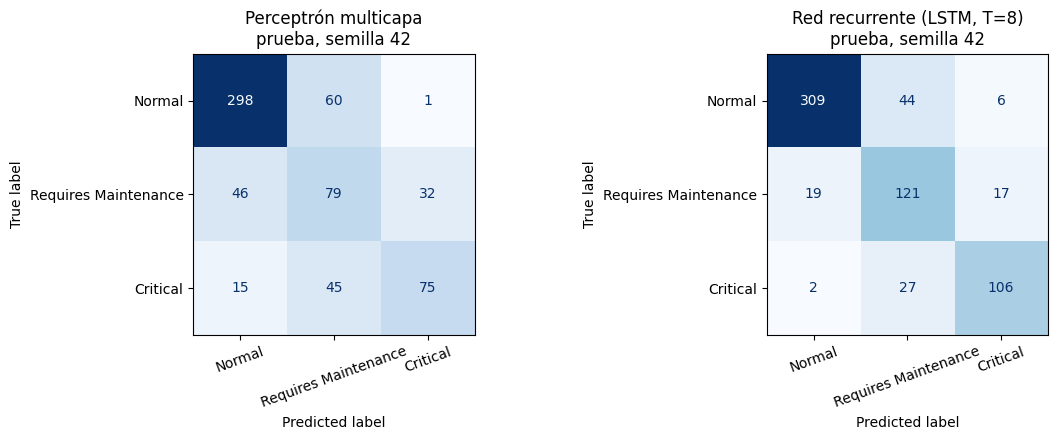

Critical clasificados como Normal, por semilla:
modelo   Perceptrón multicapa  Red recurrente (LSTM, T=8)
semilla                                                  
7                          14                           1
42                         15                           2
123                        17                           0
2024                       12                           3
31415                      13                           3


In [33]:
# Celda 37. Matrices de confusión de la semilla 42 y los errores más graves en todas las semillas.
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
for eje, clave in zip(ejes, ('mlp', 'rnn')):
    ConfusionMatrixDisplay.from_predictions(y_test, pred_test[clave][SEMILLA], display_labels=ESTADOS, ax=eje,
                                            xticks_rotation=20, cmap='Blues', colorbar=False)
    eje.set_title(f'{NOMBRE_MODELO[clave]}\nprueba, semilla {SEMILLA}')
plt.tight_layout()
plt.savefig(DIR_SALIDA + 'matrices_prueba.png', dpi=200, bbox_inches='tight')
plt.show()

print('Critical clasificados como Normal, por semilla:')
print(resultados_test[resultados_test['semilla'] != '-']
      .pivot(index='semilla', columns='modelo', values='critical_como_normal').to_string())


In [34]:
# Celda 38. ¿La diferencia entre los modelos es real? Prueba de McNemar sobre las mismas filas, semilla por semilla.
from scipy.stats import binomtest

filas = []
for s in ckpt_mlp['semillas']:
    ok_mlp = pred_test['mlp'][s] == y_test
    ok_rnn = pred_test['rnn'][s] == y_test
    solo_mlp = int((ok_mlp & ~ok_rnn).sum())   # acierta el perceptrón y falla la recurrente
    solo_rnn = int((~ok_mlp & ok_rnn).sum())   # acierta la recurrente y falla el perceptrón
    n = solo_mlp + solo_rnn
    p = binomtest(min(solo_mlp, solo_rnn), n, 0.5).pvalue if n else 1.0
    filas.append({'semilla': s, 'solo acierta MLP': solo_mlp, 'solo acierta RNN': solo_rnn, 'p (McNemar)': p})
mcnemar = pd.DataFrame(filas)
print(mcnemar.round(4).to_string(index=False))
print('\nCon p < 0,05 la diferencia de aciertos entre los dos modelos no se explica por azar en esa semilla.')


 semilla  solo acierta MLP  solo acierta RNN  p (McNemar)
      42                52               136          0.0
       7                56               141          0.0
     123                45               137          0.0
    2024                65               124          0.0
   31415                49               125          0.0

Con p < 0,05 la diferencia de aciertos entre los dos modelos no se explica por azar en esa semilla.


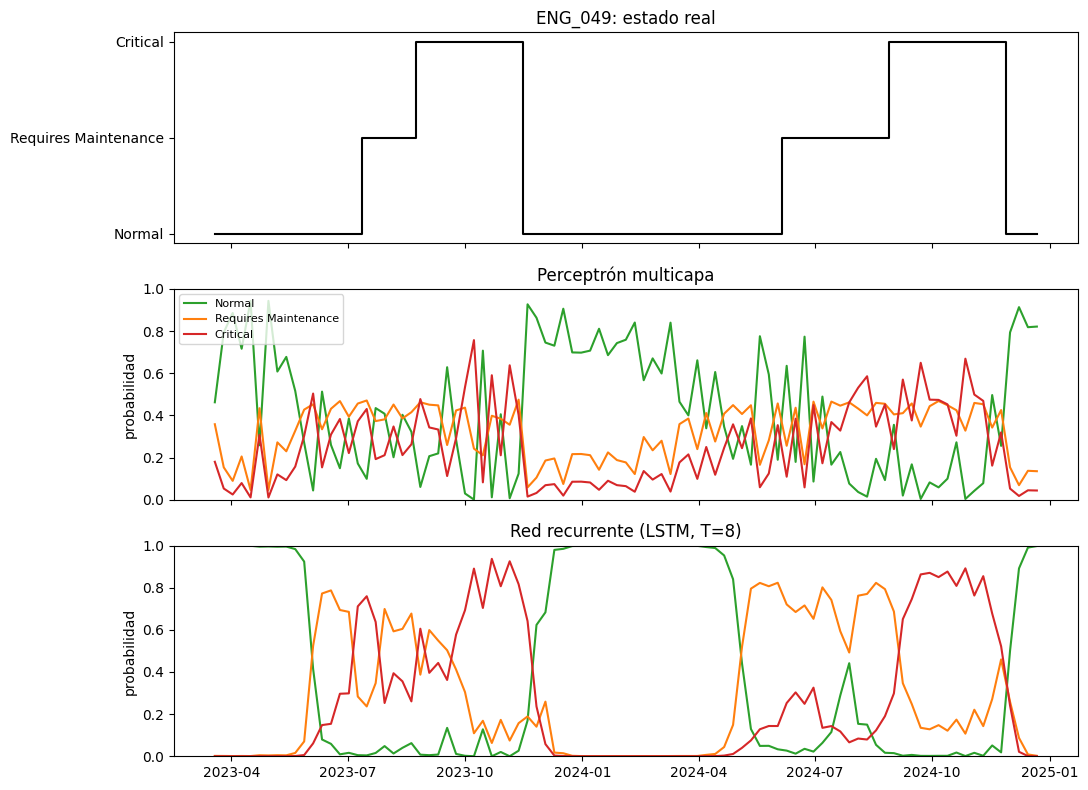

In [35]:
# Celda 39. Cercanía al mantenimiento: probabilidad semana a semana en un motor de prueba (semilla 42).
fechas_pru = df_pru['timestamp'].to_numpy()[comunes_pru]
motores_pru = df_pru['engine_id'].to_numpy()[comunes_pru]
motor = pd.Series(motores_pru[y_test == 2]).value_counts().index[0]   # el motor con más semanas Critical
sel = motores_pru == motor
colores = {'Normal': 'tab:green', 'Requires Maintenance': 'tab:orange', 'Critical': 'tab:red'}

fig, ejes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
ejes[0].step(fechas_pru[sel], y_test[sel], where='mid', color='black')
ejes[0].set_yticks(range(N_CLASES)); ejes[0].set_yticklabels(ESTADOS); ejes[0].set_title(f'{motor}: estado real')
for eje, clave in zip(ejes[1:], ('mlp', 'rnn')):
    prob = prob_test[clave][SEMILLA][sel]
    for i, nombre in enumerate(ESTADOS):
        eje.plot(fechas_pru[sel], prob[:, i], color=colores[nombre], label=nombre)
    eje.set_ylim(0, 1); eje.set_ylabel('probabilidad'); eje.set_title(NOMBRE_MODELO[clave])
ejes[1].legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.savefig(DIR_SALIDA + 'probabilidad_motor.png', dpi=200, bbox_inches='tight')
plt.show()


In [36]:
# Celda 40. Exportación para la interfaz, el informe y el repositorio.
import os

pred_df = pd.DataFrame({'engine_id': motores_pru, 'timestamp': fechas_pru,
                        'estado_real': [ESTADOS[i] for i in y_test]})
for clave in ('mlp', 'rnn'):
    pred_df[f'pred_{clave}'] = [ESTADOS[i] for i in pred_test[clave][SEMILLA]]
    for i, nombre in enumerate(ESTADOS):
        pred_df[f"prob_{clave}_{nombre.replace(' ', '_')}"] = prob_test[clave][SEMILLA][:, i].round(4)
pred_df.to_csv(DIR_SALIDA + 'predicciones_prueba.csv', index=False)

def a_json(df):
    return json.loads(df.round(4).to_json())

metricas_json = {
    'datos': 'marine_engine_data_modificado.csv (tendencia simulada, semilla 42)',
    'filas_prueba': int(len(y_test)), 'motores_prueba': sorted(df_pru['engine_id'].unique().tolist()),
    'semillas': ckpt_mlp['semillas'], 'config_mlp': cm_, 'config_rnn': cr_,
    'resumen': {modelo: {m: {'media': float(tabla_principal.loc[modelo, (m, 'mean')]),
                             'desv': None if pd.isna(tabla_principal.loc[modelo, (m, 'std')])
                             else float(tabla_principal.loc[modelo, (m, 'std')])} for m in cols}
                for modelo in tabla_principal.index},
    'por_clase': {clave: {'media': a_json(detalle_test[clave]['media']), 'desv': a_json(detalle_test[clave]['desv'])}
                  for clave in ('mlp', 'rnn')},
    'mcnemar': mcnemar.round(4).to_dict(orient='records'),
}
with open(DIR_SALIDA + 'metricas.json', 'w') as f:
    json.dump(metricas_json, f, indent=2, ensure_ascii=False, default=float)

for nombre in sorted(os.listdir(DIR_SALIDA or '.')):
    print(f"{nombre:40s} {os.path.getsize(os.path.join(DIR_SALIDA or '.', nombre)) / 1024:8.1f} KB")


.virtual_documents                            4.0 KB
busqueda_mlp.csv                              3.2 KB
busqueda_rnn.csv                              2.8 KB
config.json                                   0.3 KB
marine_engine_data_modificado.csv          1283.6 KB
matrices_prueba.png                          92.7 KB
metricas.json                                 8.3 KB
mlp.pt                                       67.0 KB
predicciones_prueba.csv                      59.7 KB
preprocesador.joblib                          4.0 KB
probabilidad_motor.png                      376.4 KB
rnn.pt                                     1105.7 KB


## Conclusiones de la evaluación

Evaluación única en el conjunto de prueba: 651 semanas de 7 motores que no se usaron para entrenar ni para elegir parámetros (359 Normal, 157 Requires Maintenance, 135 Critical). Media y desviación de cinco semillas.

| Modelo | Exactitud | F1 macro | Exhaustividad Critical | Critical tomados como Normal |
|---|---|---|---|---|
| Clase mayoritaria | 0,551 | 0,237 | 0,000 | 135 |
| Perceptrón multicapa | 0,692 ± 0,004 | 0,633 ± 0,007 | 0,517 ± 0,037 | 14,2 ± 1,9 |
| Red recurrente (LSTM, T = 8) | 0,813 ± 0,016 | 0,776 ± 0,020 | 0,735 ± 0,102 | 1,8 ± 1,3 |

1. **Resultado principal.** Los dos modelos superan con claridad la línea base. La red recurrente supera al perceptrón en todas las métricas globales: 0,14 más de F1 macro y 0,12 más de exactitud.

2. **¿El historial semanal aporta?** Sí, con estos datos. En cada semilla, la red recurrente acierta entre 124 y 141 semanas en las que el perceptrón falla, y el perceptrón solo acierta entre 45 y 65 en las que falla la red recurrente. La prueba de McNemar da p < 0,001 en las cinco semillas. Hay que leerlo con cuidado: la tendencia simulada acumula desgaste semana a semana, así que por construcción favorece a un modelo que mira varias semanas. El resultado muestra que la red recurrente aprovecha esa estructura, no que lo haría igual con motores reales.

3. **Errores graves.** De 135 semanas Critical, el perceptrón clasifica como Normal unas 14 (10,5 %) y la red recurrente menos de 2 (1,3 %). Para mantenimiento, donde pasar por alto un estado crítico es el error más caro, conviene la red recurrente. Su exhaustividad en Critical varía bastante entre semillas (± 0,10), lo que conviene reportar.

4. **Clase más difícil.** Requires Maintenance, en los dos modelos (F1 de 0,474 en el perceptrón y 0,665 en la red recurrente). Es un estado intermedio y se confunde hacia ambos lados. En el perceptrón con semilla 42, 60 semanas Normal pasan a Requires Maintenance y 45 Critical también. Causa probable: en la modificación del dataset, el desvío de los sensores crece con el cuadrado del desgaste, así que al cruzar el umbral de 0,55 los sensores solo muestran cerca del 30 % de su desvío máximo; una sola semana distingue poco ese límite.

5. **Cercanía al mantenimiento.** En el motor ENG_049, la probabilidad que da la red recurrente sigue los ciclos de desgaste: Requires Maintenance sube hasta cerca de 0,8 al entrar en ese tramo, Critical toma el relevo después y todo vuelve a Normal tras el mantenimiento. En el perceptrón las probabilidades oscilan de una semana a otra y no forman una señal estable. Para una alerta temprana, la curva de la red recurrente es la que serviría.

6. **Modelo recomendado.** La red recurrente LSTM con ventana de 8 semanas (___ unidades, ___ capas; ver `config.json`): mayor F1 macro, mayor exhaustividad en Critical y menos casos Critical tomados como Normal.

7. **Límites.** Los resultados corresponden a una tendencia de deterioro simulada sobre el dataset original, que no tenía señal. La prueba usa solo 7 motores y una única simulación de la tendencia. Antes de aplicarlo a motores reales haría falta validarlo con registros reales de mantenimiento.

In [37]:
# Versiones usadas, para requirements.txt de Git Hub
import sys, numpy, pandas, sklearn, scipy, matplotlib, joblib, torch
print("Python", sys.version.split()[0])
for nombre, m in [("numpy", numpy), ("pandas", pandas), ("scikit-learn", sklearn), ("scipy", scipy),
                  ("matplotlib", matplotlib), ("joblib", joblib), ("torch", torch)]:
    print(f"{nombre}=={m.__version__.split('+')[0]}")

Python 3.13.18
numpy==2.1.3
pandas==2.3.3
scikit-learn==1.6.1
scipy==1.16.3
matplotlib==3.10.0
joblib==1.6.0
torch==2.11.0
